# CT Acquisition Experiments

## Objective

Evaluate how the number of projection angles affects CT reconstruction quality and computational cost.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from skimage.transform import iradon, radon

from medimaging.quality.psnr import calculate_psnr
from medimaging.quality.ssim import calculate_ssim
from medimaging.simulation.phantom import create_shepp_logan

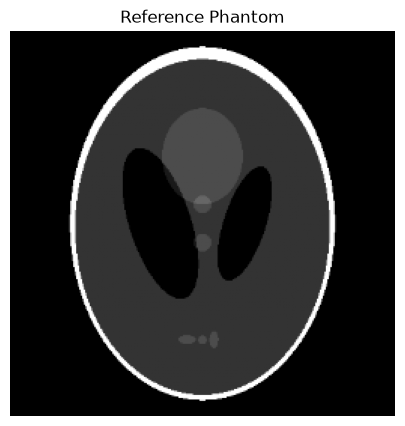

In [2]:
phantom = create_shepp_logan(256)

plt.figure(figsize=(5, 5))
plt.imshow(phantom, cmap="gray")
plt.title("Reference Phantom")
plt.axis("off")
plt.show()

In [3]:
projection_counts = [30, 60, 90, 120, 180]

results = []

for n_projections in projection_counts:
    theta = np.linspace(
        0.0,
        180.0,
        n_projections,
        endpoint=False,
    )

    sinogram = radon(
        phantom,
        theta=theta,
        circle=True,
    )

    start_time = time.perf_counter()

    reconstruction = iradon(
        sinogram,
        theta=theta,
        filter_name="ramp",
        circle=True,
    )

    elapsed_time = time.perf_counter() - start_time

    psnr = calculate_psnr(phantom, reconstruction)

    ssim = calculate_ssim(phantom, reconstruction)

    results.append(
        {
            "n_projections": n_projections,
            "psnr": psnr,
            "ssim": ssim,
            "reconstruction_time": elapsed_time,
        }
    )

print("Acquisition experiment results:")

for result in results:
    print(result)

Acquisition experiment results:
{'n_projections': 30, 'psnr': 19.662929647668914, 'ssim': 0.46347741727384995, 'reconstruction_time': 0.013549250084906816}
{'n_projections': 60, 'psnr': 26.729509424049684, 'ssim': 0.6266679678894133, 'reconstruction_time': 0.016572915948927402}
{'n_projections': 90, 'psnr': 29.23450744382261, 'ssim': 0.7621788193698823, 'reconstruction_time': 0.02150041703134775}
{'n_projections': 120, 'psnr': 30.193884897827882, 'ssim': 0.8504086606010794, 'reconstruction_time': 0.027376791927963495}
{'n_projections': 180, 'psnr': 30.774608008018905, 'ssim': 0.9218287387086153, 'reconstruction_time': 0.040560999885201454}


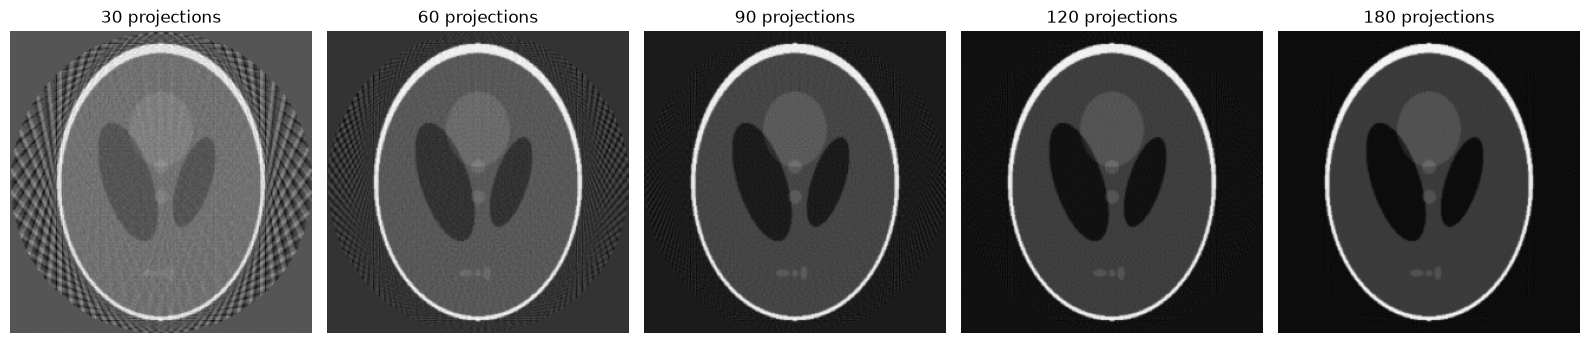

In [5]:
fig, axes = plt.subplots(1, len(results), figsize=(16, 4))

for ax, result in zip(axes, results, strict=True):
    n_projections = result["n_projections"]

    theta = np.linspace(
        0.0,
        180.0,
        n_projections,
        endpoint=False,
    )

    sinogram = radon(
        phantom,
        theta=theta,
        circle=True,
    )

    reconstruction = iradon(
        sinogram,
        theta=theta,
        filter_name="ramp",
        circle=True,
    )

    ax.imshow(reconstruction, cmap="gray")
    ax.set_title(f'{n_projections} projections')
    ax.axis("off")

plt.tight_layout()
plt.show()

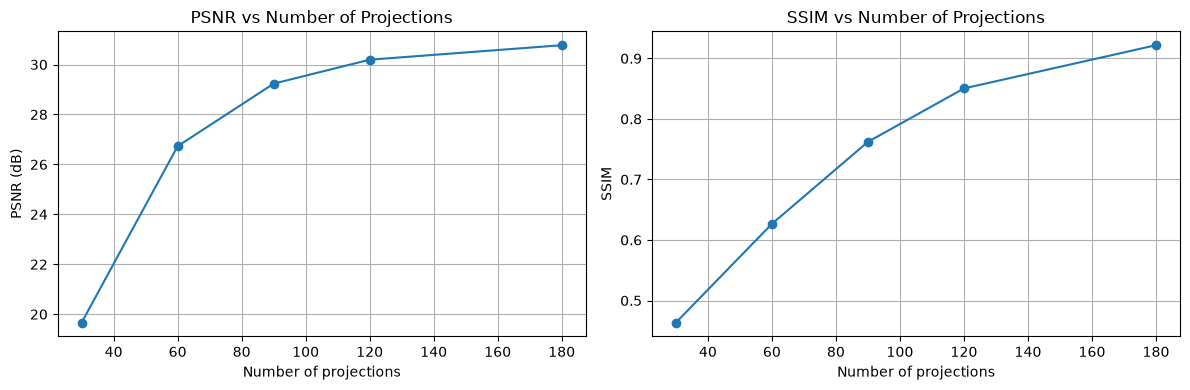

In [6]:
projection_counts = [r["n_projections"] for r in results]
psnr_values = [r["psnr"] for r in results]
ssim_values = [r["ssim"] for r in results]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(projection_counts, psnr_values, marker="o")
axes[0].set_title("PSNR vs Number of Projections")
axes[0].set_xlabel("Number of projections")
axes[0].set_ylabel("PSNR (dB)")
axes[0].grid(True)

axes[1].plot(projection_counts, ssim_values, marker="o")
axes[1].set_title("SSIM vs Number of Projections")
axes[1].set_xlabel("Number of projections")
axes[1].set_ylabel("SSIM")
axes[1].grid(True)

plt.tight_layout()
plt.show()

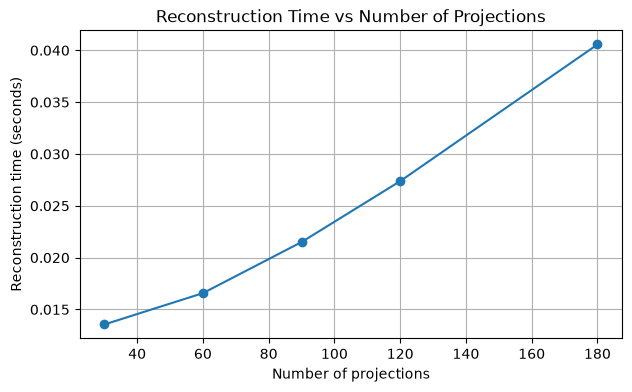

In [7]:
time_values = [r["reconstruction_time"] for r in results]

plt.figure(figsize=(7, 4))
plt.plot(projection_counts, time_values, marker="o")
plt.title("Reconstruction Time vs Number of Projections")
plt.xlabel("Number of projections")
plt.ylabel("Reconstruction time (seconds)")
plt.grid(True)
plt.show()

## Conclusions

Increasing the number of projection angles improved reconstruction quality, as measured by PSNR and SSIM, while increasing FBP reconstruction time.

The largest quality improvement occurred between 30 and 60 projections, with progressively smaller PSNR gains at higher sampling levels.

These results illustrate the trade-off between angular sampling, image quality, and computational cost in simulated CT reconstruction. Acquisition time and radiation dose were not evaluated.